<a id="chapter-17"></a>

# Chapter 17 · Black-Box Optimizations in RL / 黑盒优化

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 evolution strategies 与 genetic algorithms
- 无需反向传播估计搜索方向
- 认识参数空间搜索的优缺点

**开始前最好已经会：**

- 理解参数向量和随机采样
- 知道 Gaussian 分布
- 会计算标准化分数


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Black-box methods | 适用边界 | 详细 |
| Evolution strategies | 梯度估计推导与 CartPole/HalfCheetah | 详细 |
| Genetic algorithms | 选择、变异、deep GA、novelty | 详细 |
| GA on CartPole / HalfCheetah | 源码路线 | 完整 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

如果环境不可微、奖励离散、甚至策略里包含复杂规则，还能优化吗？黑盒方法只问一个问题：这组参数得分多少？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

黑盒方法只需要“参数 → 适应度”，不要求环境或策略可微。它们易并行、对长时依赖直接，但通常样本开销很大。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\theta$ | 当前策略参数 | 搜索中心 |
| $\epsilon$ | Gaussian 扰动 | 探索方向 |
| $\sigma$ | 扰动尺度 | 搜索半径 |
| $F(\theta)$ | 适应度/episode return | 无需可微 |
| population | 每代候选数量 | 方差与计算量权衡 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 优化一个平滑后的目标

ES 实际考虑 Gaussian 平滑目标

$$J(\theta)=\mathbb E_{\epsilon\sim\mathcal N(0,I)}[F(\theta+\sigma\epsilon)]$$

利用 score-function identity，可得

$$\nabla_\theta J=\frac1\sigma\mathbb E[F(\theta+\sigma\epsilon)\epsilon]$$

Monte Carlo 近似：

$$\hat g=\frac1{n\sigma}\sum_{i=1}^nF_i\epsilon_i$$

直觉是：高分扰动方向获得正权重，低分方向获得负权重，中心朝更可能高分的方向移动。

### 2. 为什么标准化 fitness

给所有 fitness 加常数理论上不应改变期望梯度，因为 $\mathbb E[\epsilon]=0$，但有限 population 会有噪声。减均值、除标准差或 rank transform 可降低尺度和异常值影响。

### 3. 与 policy gradient 的差别

policy gradient 在动作空间采样并利用每步 log-prob；ES 在参数空间采样并只用整条轨迹 fitness。ES 易于跨 worker 并行，但高维参数下通常需要大量环境评估。


## 4. 手算一个最小例子


一维情况下，若正扰动 $+0.2$ 得分 10，负扰动 $-0.2$ 得分 4，那么加权扰动和为正，参数会向正方向移动。antithetic sampling 总是成对评估 $+\epsilon,-\epsilon$，直接比较两个方向，常能降低方差。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Evolution Strategies (ES)

采样 $\epsilon_i\sim\mathcal N(0,I)$，评估 $F(\theta+\sigma\epsilon_i)$，梯度估计：

$$\nabla_\theta\mathbb E_\epsilon[F(\theta+\sigma\epsilon)]\approx\frac1{n\sigma}\sum_{i=1}^nF_i\epsilon_i$$

antithetic sampling 同时评估 $+\epsilon$ 与 $-\epsilon$ 可降低方差；fitness rank normalization 可降低尺度敏感性。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $\epsilon_i$ | `noise`，shape `(population, dim)` | 每个候选的随机方向 |
| $\theta+\sigma\epsilon_i$ | `theta + sigma * noise` | 候选参数 |
| $F_i$ | `scores` | 批量 fitness |
| 标准化 $F_i$ | `(scores-mean)/(std+eps)` | 降低尺度影响 |
| $\hat g$ | `(scores[:,None] * noise).mean(0) / sigma` | ES 梯度估计 |
| 参数更新 | `theta += lr * grad` | 因为这里直接最大化 fitness |

**从公式过渡到代码时：**用 ES 最大化二维凹二次函数，观察参数逐渐靠近最优点。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

rng = np.random.default_rng(7)
theta = np.array([4.0, -3.0])
optimum = np.array([1.5, 2.0])
sigma, lr, population = 0.2, 0.08, 200

def fitness(x):
    return -np.sum((x - optimum) ** 2, axis=-1)

for _ in range(120):
    noise = rng.normal(size=(population, 2))
    scores = fitness(theta + sigma * noise)
    scores = (scores - scores.mean()) / (scores.std() + 1e-8)
    grad = (scores[:, None] * noise).mean(axis=0) / sigma
    theta += lr * grad

print("theta:", np.round(theta, 3), "fitness:", round(float(fitness(theta)), 5))


theta: [1.531 2.034] fitness: -0.00212


### 怎样读运行结果

二维凹函数的最优点是 `[1.5,2.0]`，最终 theta 应接近它。不同 seed 会有波动；比较 population 时应同时报告总 fitness evaluations。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
ES：
初始化参数中心 θ
repeat:
  生成成对噪声 ±εi
  并行评估 F(θ+σεi), F(θ-σεi)
  对 fitness 做 centered rank/标准化
  g = mean(Fi εi) / σ
  θ += learning_rate * optimizer(g)

GA：
评估 population → 选 elite → 复制/交叉/变异 → 新一代
可用 novelty score 替代或混合任务 fitness
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

rng = np.random.default_rng(0)
eps = rng.normal(size=5)
# 一维目标 F(theta)=-(theta-2)^2，在 theta=0 比较 antithetic pairs。
theta, sigma = 0.0, 0.1
f_plus = -((theta + sigma*eps) - 2)**2
f_minus = -((theta - sigma*eps) - 2)**2
grad = np.mean((f_plus - f_minus) * eps) / (2*sigma)
print("antithetic gradient estimate:", grad, "true gradient:", 4.0)


antithetic gradient estimate: 0.5930773332189957 true gradient: 4.0


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_cartpole_es.py`](../../Chapter17/01_cartpole_es.py) | CartPole ES | 参数扰动、fitness 与更新 |
| [`02_cheetah_es.py`](../../Chapter17/02_cheetah_es.py) | 并行 HalfCheetah ES | 共享噪声/worker 评估 |
| [`03_cartpole_ga.py`](../../Chapter17/03_cartpole_ga.py) | CartPole GA | elite 与变异 |
| [`04_cheetah_ga.py`](../../Chapter17/04_cheetah_ga.py) | HalfCheetah GA | 高维参数和并行 |
| [`common.py`](../../Chapter17/lib/common.py) | 参数向量化工具 | state_dict 与 flat vector 往返 |

<details>
<summary>为什么按这个顺序读</summary>

黑盒方法的首要工程问题是把模型参数稳定地展平和恢复，参数顺序必须固定。ES worker 可只接收 noise seed 而不是整组参数，降低通信量；主进程用相同 seed 重建扰动。GA 的 elite 复用容易降低多样性，novelty search 用行为描述符鼓励不同策略，但描述符选择会决定什么叫‘新颖’。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**Evolution Strategies 搜索到的最佳目标值

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


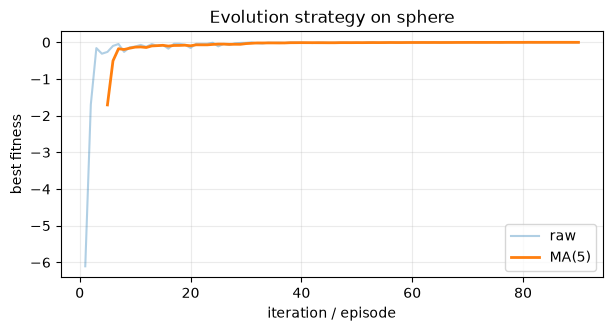

solution: [-0.008  0.007  0.004] distance to optimum: 0.012


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(17)
mean = np.array([4.0, -3.0, 2.0])
sigma, history = 1.2, []
for generation in range(90):
    noise = rng.normal(size=(80, len(mean)))
    candidates = mean + sigma * noise
    fitness = -np.sum(candidates ** 2, axis=1)
    elite_idx = np.argsort(fitness)[-12:]
    mean = candidates[elite_idx].mean(axis=0)
    sigma = max(.03, sigma * .97)
    history.append(fitness[elite_idx].max())

plot_curve(history, "Evolution strategy on sphere", "best fitness", window=5)
print("solution:", np.round(mean, 3), "distance to optimum:", round(np.linalg.norm(mean), 3))


### 曲线怎么读

fitness 应趋近 0（本问题最大值），但 sigma 太快缩小会过早停滞。黑盒优化没有 policy/value loss，重点看 best/median fitness、种群多样性和 wall-clock。

### 调参过程：一次只改变一个因素

- 先用固定 sigma 建立种群大小与吞吐基线。
- 再加入 sigma decay；若 median 很早停滞，减慢衰减。
- 并行扩大 population 时按 wall-clock 和总评估次数双重比较。

### 失败案例复盘

- 只保留单个最好个体，种群多样性迅速消失。
- 不同 worker 使用相同噪声种子。
- 与梯度法比较时忽略 ES 使用了更多环境评估。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 多个随机 seed 复评 elite，避免选中纯噪声高分。
- worker 只需共享随机 seed/参数扰动时，通信成本可很低。
- 先在低维函数验证符号和尺度，再跑昂贵环境。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把 population 改成 10 和 1000，比较不同 seed 下的稳定性与评估次数。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

population=10 评估少但梯度噪声大，不同 seed 可能偏离最优；1000 更稳定但每代环境成本高 100 倍。比较时必须用相同总 evaluation budget，而不能只比较迭代轮数。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- ES 不需要对环境或策略求导。
- 它优化 Gaussian 平滑后的 fitness。
- fitness 加权的扰动平均给出搜索方向。
- 并行简单不等于样本高效。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么代码使用 `theta +=` 而神经网络 loss 通常使用梯度下降？ES 的主要成本是什么？

<details>
<summary>展开答案</summary>

这里估计的是 fitness 上升方向，所以直接加；神经网络通常定义要最小化的 loss。ES 主要成本是大量候选都要完成环境评估。
</details>


## 17. 与前后章节连接

第 18 章的 NoisyNet 也在参数中注入噪声，但目的和更新方式不同：它仍通过 TD/策略梯度学习。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

GA 使用选择、交叉、变异；novelty search 奖励行为差异而非任务分数，可缓解 deceptive reward。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-17) · [← 学习索引](../README.md)
